Dataset Exploration

In [1]:
pip install pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
# connect to the parquet file and SQL view called flows

import json
import ipaddress
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt


class FlowData:
    def __init__(self, root):
        self.path = root / "student_dataset" / "flows.parquet"
        self.splits = json.loads((root / "student_dataset" / "splits.json").read_text())
        self.con = duckdb.connect()
        self.con.execute("SET TimeZone='UTC'")
        self.con.execute(f"CREATE VIEW flows AS SELECT * FROM read_parquet('{self.path.as_posix()}')")

    def query(self, sql):
        return self.con.execute(sql).fetchdf()

    def count(self):
        return self.query("SELECT count(*) AS n FROM flows").n[0]

    def size_gb(self):
        return self.path.stat().st_size / 1e9

    def split_label(self):
        train_end = self.splits["train_end_inclusive"]
        val_end = self.splits["validation_end_inclusive"]
        return (
            f"CASE WHEN cast(flow_start AS TIMESTAMPTZ) <= TIMESTAMPTZ '{train_end}' THEN 'train' "
            f"WHEN cast(flow_start AS TIMESTAMPTZ) <= TIMESTAMPTZ '{val_end}' THEN 'validation' "
            f"ELSE 'test' END"
        )

    def expected_counts(self):
        counts = {}
        for name, info in self.splits["splits"].items():
            counts[name] = info["row_count"]
        return counts

In [3]:
ROOT = Path.cwd()
print(ROOT)
if not (ROOT/ "Data"/"student_dataset").is_dir():
    ROOT = ROOT.parent
ROOT = ROOT /"Data"
print(ROOT)
data = FlowData(ROOT)
SPLIT = data.split_label()

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

print("rows", data.count())
print("size_gb", round(data.size_gb(), 2))

c:\Users\vince\Documents\EPFL\MA1\ML\CERN_Project\CERN_RTT_Prediction\notebooks
c:\Users\vince\Documents\EPFL\MA1\ML\CERN_Project\CERN_RTT_Prediction\Data
rows 67244519
size_gb 4.84


## 1. Schema

In [4]:
# read parquet metadata to see how many bytes each column
import pyarrow.parquet as pq

meta = pq.ParquetFile(data.path).metadata

rows = []
for i in range(meta.num_columns):
    column = meta.row_group(0).column(i)
    size = 0
    for g in range(meta.num_row_groups):
        size = size + meta.row_group(g).column(i).total_compressed_size
    rows.append([column.path_in_schema, str(column.physical_type), size / 1e6])

schema = pd.DataFrame(rows, columns=["column", "type", "mb"])
schema = schema.sort_values("mb", ascending=False).reset_index(drop=True)
schema["share"] = (100 * schema.mb / schema.mb.sum()).round(1)
schema

,column,type,mb,share
0,flow_id,BYTE_ARRAY,2303.696763,47.6
1,flow_end,BYTE_ARRAY,507.025743,10.5
2,flow_start,BYTE_ARRAY,461.494848,9.5
3,end_rtt,DOUBLE,271.840531,5.6
4,start_rtt,DOUBLE,248.941219,5.1
5,delta_rtt,DOUBLE,239.617150,5.0
6,meta.src_ip,BYTE_ARRAY,156.498859,3.2
7,meta.src_port,INT64,144.538058,3.0
8,meta.dst_ip,BYTE_ARRAY,99.446687,2.1
9,meta.syslog.hostname,BYTE_ARRAY,84.568559,1.7


In [5]:
# add columns that will cause leakage
leakage = ["flow_id", "flow_end", "end_rtt",
           "endpoints_match", "endpoints_reversed", "start_fields_match"]

unusable = schema[schema.column.isin(leakage)].mb.sum()
total = schema.mb.sum()

print("unusable_gb", round(unusable / 1000, 2))
print("total_gb", round(total / 1000, 2))
print("share", round(100 * unusable / total))

unusable_gb 3.1
total_gb 4.84
share 64


## 2. Timestamps

In [6]:
# timestamp parsed and range covered
data.query("""
    SELECT count(*) AS n,
           sum(CASE WHEN try_cast(flow_start AS TIMESTAMPTZ) IS NULL THEN 1 ELSE 0 END) AS unparseable,
           count(DISTINCT length(flow_start)) AS string_lengths,
           min(cast(flow_start AS TIMESTAMPTZ)) AS first,
           max(cast(flow_start AS TIMESTAMPTZ)) AS last
    FROM flows
""")

,n,unparseable,string_lengths,first,last
0,67244519,0.0,1,2026-10-07 23:59:59.465736+00:00,2026-10-14 23:59:59.753340+00:00


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

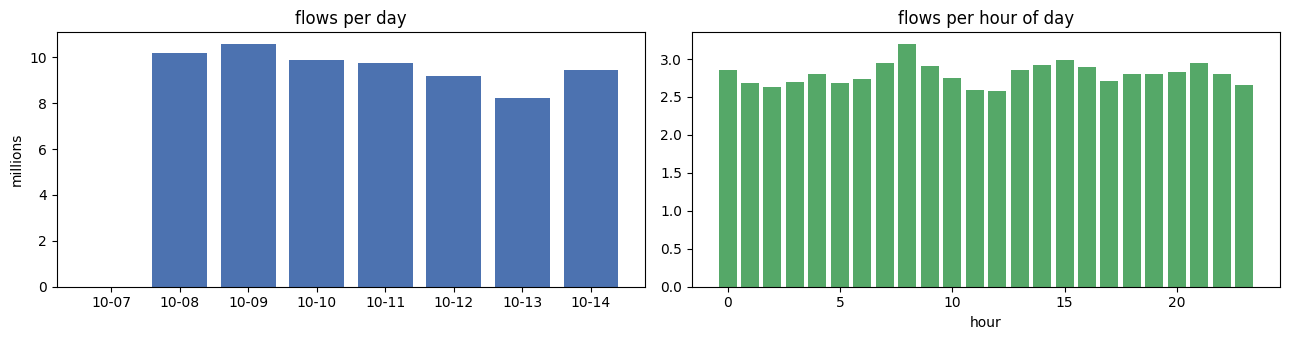

,day,n
0,2026-10-07 00:00:00+00:00,26
1,2026-10-08 00:00:00+00:00,10181245
2,2026-10-09 00:00:00+00:00,10555038
3,2026-10-10 00:00:00+00:00,9872362
4,2026-10-11 00:00:00+00:00,9757811
5,2026-10-12 00:00:00+00:00,9196187
6,2026-10-13 00:00:00+00:00,8230756
7,2026-10-14 00:00:00+00:00,9451094


In [7]:
# flows per day and per hour of day
daily = data.query("""
    SELECT date_trunc('day', cast(flow_start AS TIMESTAMPTZ)) AS day, count(*) AS n
    FROM flows GROUP BY 1 ORDER BY 1
""")
hourly = data.query("""
    SELECT extract(hour FROM cast(flow_start AS TIMESTAMPTZ)) AS hour, count(*) AS n
    FROM flows GROUP BY 1 ORDER BY 1
""")

figure, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].bar(daily.day.dt.strftime("%m-%d"), daily.n / 1e6, color="#4C72B0")
axes[0].set_title("flows per day")
axes[0].set_ylabel("millions")
axes[1].bar(hourly.hour, hourly.n / 1e6, color="#55A868")
axes[1].set_title("flows per hour of day")
axes[1].set_xlabel("hour")
plt.tight_layout()
plt.show()

daily

Volume is steady except day 1

## 3. IP addresses

In [8]:
# split the rows by IP version
data.query("""
    SELECT "meta.ip_version" AS version, count(*) AS n,
           round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS percent
    FROM flows GROUP BY 1 ORDER BY 2 DESC
""")

,version,n,percent
0,6,51736861,76.94
1,4,15507658,23.06


In [9]:
# IPv6 addresses that are written in compressed format
data.query("""
    SELECT count(*) AS v6_rows,
           sum(CASE WHEN contains("meta.src_ip", '::') THEN 1 ELSE 0 END) AS compressed,
           round(100.0 * avg(CASE WHEN contains("meta.src_ip", '::') THEN 1 ELSE 0 END), 1) AS percent_zero_compression_ipv6
    FROM flows WHERE "meta.ip_version" = 6
""")

,v6_rows,compressed,percent_zero_compression_ipv6
0,51736861,31582197.0,61.0


IPv6 is the majority and most of it is `::` compressed, so `address.split(':')[:3]` gives the
wrong prefix.

In [10]:
# Multiple levels of details for addresses
#   host       27,228 src values  most specific
#   narrow     898             
#   medium     674
#   broad      297                least specific
# we can keep them and decide with experimentation later

class IpPrefixes:
    def __init__(self):
        self.bits = {4: [16, 24, 24], 6: [32, 48, 64]}

    def for_address(self, address):
        ip = ipaddress.ip_address(address)
        prefixes = []
        for size in self.bits[ip.version]:# IPv4 or IPv6 and pick the corresponding size
            # ip_network("192.0.2.10/24") raises ValueError for having host bits set
            # ip_network("192.0.2.10/24", strict=False) or ("192.0.2.0/24") are ok
            network = ipaddress.ip_network(f"{address}/{size}", strict=False)
            # store as text
            prefixes.append(str(network))
         # order matches self.bits: broad, medium, narrow.
        return ip.version, prefixes[0], prefixes[1], prefixes[2]

    def table(self, addresses):
        rows = []
        for address in addresses:
            version, broad, medium, narrow = self.for_address(address)
            rows.append([address, version, broad, medium, narrow])
        return pd.DataFrame(rows, columns=["ip", "version", "broad", "medium", "narrow"])


prefixes = IpPrefixes()
for case in ["192.0.2.10", "2001:630:10:f00e::4001", "::1"]:
    print(case, prefixes.for_address(case))

192.0.2.10 (4, '192.0.0.0/16', '192.0.2.0/24', '192.0.2.0/24')
2001:630:10:f00e::4001 (6, '2001:630::/32', '2001:630:10::/48', '2001:630:10:f00e::/64')
::1 (6, '::/32', '::/48', '::/64')


In [11]:
# normalize only the distinct addresses, and a lookup table to SQL
addresses = data.query("""
    SELECT DISTINCT ip FROM (
        SELECT "meta.src_ip" AS ip FROM flows
        UNION
        SELECT "meta.dst_ip" FROM flows
    ) WHERE ip IS NOT NULL
""")["ip"].tolist()

lookup = prefixes.table(addresses)
data.con.register("ip_lookup", lookup)

print("distinct_addresses", len(addresses))
lookup.sample(5, random_state=0)

distinct_addresses 28643


,ip,version,broad,medium,narrow
14147,2001:67c:1148:301::404,6,2001:67c::/32,2001:67c:1148::/48,2001:67c:1148:301::/64
10007,2001:630:58:1c20::82f6:2f93,6,2001:630::/32,2001:630:58::/48,2001:630:58:1c20::/64
12664,2001:760:4228::110,6,2001:760::/32,2001:760:4228::/48,2001:760:4228::/64
22035,169.228.130.220,4,169.228.0.0/16,169.228.130.0/24,169.228.130.0/24
4981,2a0c:5bc0:c8:2:1e34:daff:fe7c:6576,6,2a0c:5bc0::/32,2a0c:5bc0:c8::/48,2a0c:5bc0:c8:2::/64


In [12]:
# distinct values at each prefix depth
rows = []
for side, column in [("src", "meta.src_ip"), ("dst", "meta.dst_ip")]:
    result = data.query(f"""
        SELECT count(DISTINCT t."{column}") AS host,
               count(DISTINCT l.narrow) AS narrow,
               count(DISTINCT l.medium) AS medium,
               count(DISTINCT l.broad) AS broad
        FROM flows t JOIN ip_lookup l ON l.ip = t."{column}"
    """).iloc[0]
    rows.append([side, result.host, result.narrow, result.medium, result.broad])

pd.DataFrame(rows, columns=["side", "host", "narrow", "medium", "broad"])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,side,host,narrow,medium,broad
0,src,27228,898,674,297
1,dst,6823,601,437,255


## 4. Ports

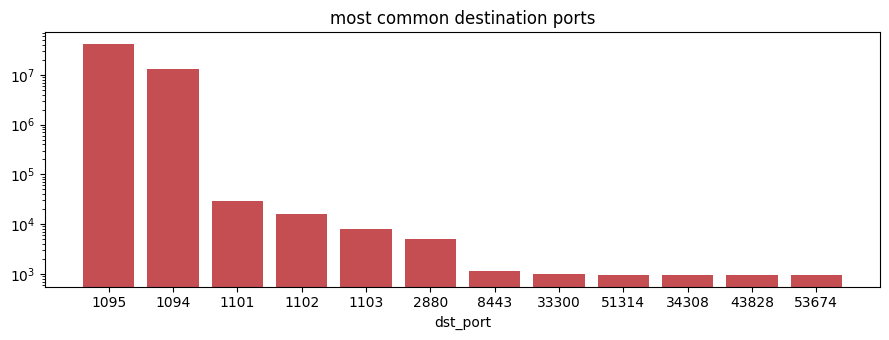

,dst_port,n,percent
0,1095,41823909,62.20
1,1094,12934416,19.23
2,1101,28724,0.04
3,1102,15592,0.02
4,1103,7795,0.01
5,2880,5011,0.01
6,8443,1164,0.00
7,33300,1002,0.00
8,51314,952,0.00
9,34308,946,0.00


In [13]:
# busiest destination ports
ports = data.query("""
    SELECT "meta.dst_port" AS dst_port, count(*) AS n
    FROM flows GROUP BY 1 ORDER BY 2 DESC LIMIT 12
""")

figure, axis = plt.subplots(figsize=(9, 3.5))
axis.bar(ports.dst_port.astype(str), ports.n, color="#C44E52")
axis.set_yscale("log")
axis.set_xlabel("dst_port")
axis.set_title("most common destination ports")
plt.tight_layout()
plt.show()

ports["percent"] = (100 * ports.n / data.count()).round(2)
ports

Not a uniform range, and 1095 1094 carry most traffic

## 5. Categorical features

In [14]:
# distinct values and nulls for every categorical column
columns = ["meta.src_ip", "meta.dst_ip", "meta.src_port", "meta.dst_port",
           "meta.cric.src.name", "meta.cric.dst.name", "meta.cric.src.asn", "meta.cric.dst.asn",
           "meta.application", "meta.experiment_name", "meta.activity_id",
           "meta.protocol", "meta.ip_version", "meta.syslog.hostname"]

parts = []
for column in columns:
    parts.append(f'count("{column}") AS "{column}|filled"')
    parts.append(f'approx_count_distinct("{column}") AS "{column}|distinct"')

result = data.query(f"SELECT count(*) AS n, {', '.join(parts)} FROM flows").iloc[0]

rows = []
for column in columns:
    distinct = int(result[f"{column}|distinct"])
    nulls = round(100 * (result.n - result[f"{column}|filled"]) / result.n, 2)
    rows.append([column, distinct, nulls])

pd.DataFrame(rows, columns=["column", "distinct", "null_percent"]).sort_values("distinct")

,column,distinct,null_percent
11,meta.protocol,1,0.00
12,meta.ip_version,2,0.00
9,meta.experiment_name,6,0.00
10,meta.activity_id,22,0.00
7,meta.cric.dst.asn,58,4.03
6,meta.cric.src.asn,63,18.35
5,meta.cric.dst.name,77,4.03
4,meta.cric.src.name,89,18.35
8,meta.application,186,0.71
13,meta.syslog.hostname,789,0.00


**CRIC enrichment is missing for about 18% of sources**
Maybe need to make its own category or flag it
Only one value for meta.protocol so we can drop it

## 6. Target delta_rtt

In [15]:
# Basic statistics for the target, including a check that delta_rtt is exact.
data.query("""
    SELECT count(*) AS n, min(delta_rtt) AS min, max(delta_rtt) AS max,
           avg(delta_rtt) AS mean, stddev(delta_rtt) AS std,
           sum(CASE WHEN delta_rtt < 0 THEN 1 ELSE 0 END) AS negative,
           sum(CASE WHEN delta_rtt = 0 THEN 1 ELSE 0 END) AS zero,
           sum(CASE WHEN delta_rtt <> end_rtt - start_rtt THEN 1 ELSE 0 END) AS not_exact
    FROM flows
""")

,n,min,max,mean,std,negative,zero,not_exact
0,67244519,-14993.52,120016.873,3.359794,113.216026,9679068.0,242527.0,0.0


In [16]:
# distribution of the target
levels = [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
values = data.query(f"SELECT quantile_cont(delta_rtt, {levels}) AS v FROM flows").v[0]

pd.DataFrame({"quantile": levels, "delta_rtt": values})

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,quantile,delta_rtt
0,0.001,-89.23882
1,0.010,-7.85600
2,0.050,-0.29700
3,0.250,0.06200
4,0.500,4.45100
5,0.750,5.24600
6,0.950,6.81300
7,0.990,15.32300
8,0.999,41.46300


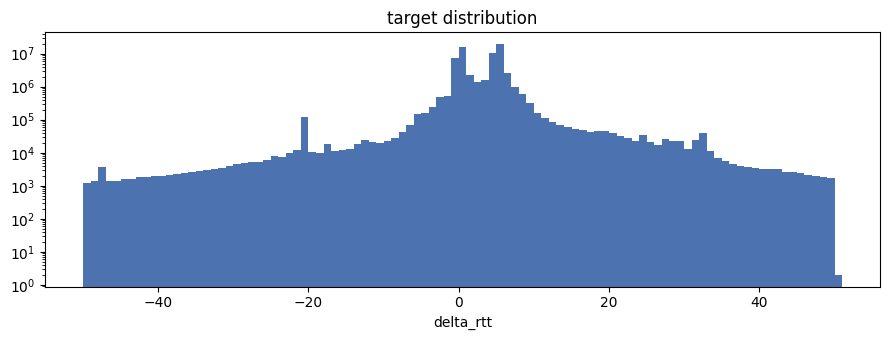

In [17]:
histogram = data.query("""
    SELECT floor(delta_rtt) AS bucket, count(*) AS n
    FROM flows WHERE delta_rtt BETWEEN -50 AND 50 GROUP BY 1 ORDER BY 1
""")

figure, axis = plt.subplots(figsize=(9, 3.5))
axis.bar(histogram.bucket, histogram.n, width=1.0, align="edge", color="#4C72B0")
axis.set_yscale("log")
axis.set_xlabel("delta_rtt")
axis.set_title("target distribution")
plt.tight_layout()
plt.show()

## 7. Splits

In [18]:
# split row counts match splits.json.
counts = data.query(f"""
    SELECT {SPLIT} AS split, count(*) AS n,
           min(cast(flow_start AS TIMESTAMPTZ)) AS first,
           max(cast(flow_start AS TIMESTAMPTZ)) AS last
    FROM flows GROUP BY 1 ORDER BY 3
""")

counts["expected"] = counts.split.map(data.expected_counts())
counts["matches"] = counts.n == counts.expected
counts

,split,n,first,last,expected,matches
0,train,47071163,2026-10-07 23:59:59.465736+00:00,2026-10-12 17:12:05.477960+00:00,47071163,True
1,validation,10086678,2026-10-12 17:12:05.481692+00:00,2026-10-13 22:18:28.700870+00:00,10086678,True
2,test,10086678,2026-10-13 22:18:28.701549+00:00,2026-10-14 23:59:59.753340+00:00,10086678,True


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

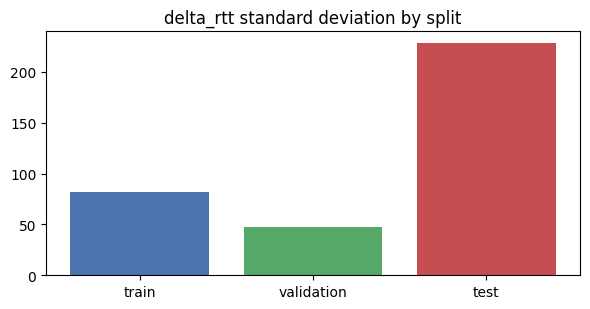

,split,n,mean,std,median
0,train,47071163,2.854113,81.502967,4.369
1,validation,10086678,3.340499,47.249787,4.435
2,test,10086678,5.738931,228.503044,4.716


In [19]:
# compare the target distribution across the three splits
drift = data.query(f"""
    SELECT {SPLIT} AS split, count(*) AS n, avg(delta_rtt) AS mean,
           stddev(delta_rtt) AS std, median(delta_rtt) AS median,
           min(epoch(cast(flow_start AS TIMESTAMPTZ))) AS start
    FROM flows GROUP BY 1 ORDER BY start
""")

figure, axis = plt.subplots(figsize=(6, 3.2))
axis.bar(drift.split, drift["std"], color=["#4C72B0", "#55A868", "#C44E52"])
axis.set_title("delta_rtt standard deviation by split")
plt.tight_layout()
plt.show()

drift.drop(columns="start")

In [20]:
# score constant predictions fitted on train against test
train = data.query(f"""
    SELECT median(delta_rtt) AS median, avg(delta_rtt) AS mean
    FROM flows WHERE {SPLIT} = 'train'
""").iloc[0]

rows = []
for label, value in [("train median", train["median"]), ("train mean", train["mean"]), ("zero", 0.0)]:
    result = data.query(f"""
        SELECT avg(abs(delta_rtt - {value})) AS mae,
               sqrt(avg((delta_rtt - {value})^2)) AS rmse
        FROM flows WHERE {SPLIT} = 'test'
    """).iloc[0]
    rows.append([label, round(value, 3), round(result.mae, 3), round(result.rmse, 3)])

pd.DataFrame(rows, columns=["prediction", "value", "mae", "rmse"])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,prediction,value,mae,rmse
0,train median,4.369,5.238,228.507
1,train mean,2.854,5.533,228.521
2,zero,0.000,6.442,228.575
